# SmallMinesDS — dataset analysis for the Introduction and Methodology chapters

Every figure and number here comes straight from the SmallMinesDS rasters and split files;
no model is trained. Outputs are written for pasting into the write-up:

- `output/dataset_analysis/figures/*.png` — 300 dpi, sized for an A4 text column
- `output/dataset_analysis/tables/*.csv` — the tables behind each figure
- `output/dataset_analysis/numbers_for_doc.md` — every statistic quoted in the text, in one place

| § | Output | Where it goes in the document |
|---|---|---|
| 2 | split summary table, tile split CSV | §2.3 placeholder table; the published tile-ID list |
| 3 | split balance figure | §2.3 "comparable representation of stable, expanding and mine-free areas" |
| 4 | split map + adjacency statistic | §2.3 / §2.10 residual spatial autocorrelation |
| 5 | per-channel value table | Table 1; §2.4 "backscatter range is checked" |
| 6 | mine vs background per channel + AUC | §1.3 / RQ1 motivation |
| 7 | S1–S2 Spearman correlation | §1.2 comparison with Ade et al. (2026), −0.72 |
| 8 | elevation inside vs outside mines | §1.7 / §2.10 label-derivation limitation |
| 9 | mine patch sizes | §1.1 "small, dispersed"; §2.4 speckle-filter argument |
| 10 | 2016 → 2022 pixel transitions | §1.1 "emerge, expand or be abandoned" |
| 11 | haze proxy | §2.10 limited cloud variation |
| 12–13 | example tile by arm, 2016 vs 2022 | §2.2 / Table 2; §2.3 why years stay together |
| 14 | prespecified qualitative tiles | §2.8 qualitative analysis |
| 15 | environment | §2.10 implementation |

## 0. Setup

In [1]:
import json, platform, sys, time, warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage, stats
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)

SEED = 42
YEARS = ("2016", "2022")
SPLITS = ("train", "val", "test")
IMAGE_NODATA, MASK_NODATA = -9999.0, 255
PIXEL_HA = 0.01            # one 10 m x 10 m pixel
TILE_M = 1280              # 128 px x 10 m

# Which tile split to analyse:
#   "change" -- stratified on 2016->2022 change category, as described in Methodology §2.3
#   "mean"   -- stratified on mean coverage quintiles, as make_pooled_split() in terramind_binary.ipynb
STRATIFY = "change"

BANDS = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12", "VV", "VH", "DEM"]
BAND_LONG = ["blue", "green", "red", "red edge 1", "red edge 2", "red edge 3", "NIR",
             "narrow NIR", "SWIR 1", "SWIR 2", "backscatter", "backscatter", "elevation"]
SENSOR = ["Sentinel-2 L2A"] * 10 + ["Sentinel-1 RTC"] * 2 + ["Copernicus DEM"]
UNITS = ["reflectance x 10^4"] * 10 + ["dB"] * 2 + ["m"]
S2, S1, DEM = list(range(10)), [10, 11], 12
BLUE, GREEN, RED, NIR, SWIR1 = 0, 1, 2, 6, 8


def find_dir(name, *nested):
    for cand in (Path(name), Path("SmallMinesDS", name), Path("SmallMinesDS", "SmallMinesDS")):
        if all((cand / n).exists() for n in nested):
            return cand
    raise FileNotFoundError(name)


DATA = find_dir("Dataset", "2016/IMAGE", "2022/MASK")
SPLITS_DIR = find_dir("data_splits", "train_test_splits_2016.csv")
OUT = Path("output/dataset_analysis")
FIG, TAB = OUT / "figures", OUT / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

NUMBERS = {}  # every statistic quoted in the document, written out in §16


def patch_paths(year, tile):
    return (DATA / year / "IMAGE" / f"IMG_GH_{tile}_{year}.tif",
            DATA / year / "MASK" / f"MASK_GH_{tile}_{year}.tif")


print("data:", DATA.resolve(), "| splits:", SPLITS_DIR.resolve(), "| out:", OUT.resolve())

data: C:\Users\Owner\Desktop\Augustus Amedume Comp Sci Degree\Augustus Amedume Year 4 Computer Science\Semester 2\Technology Research Methods\IllegalMiningDetection\Dataset | splits: C:\Users\Owner\Desktop\Augustus Amedume Comp Sci Degree\Augustus Amedume Year 4 Computer Science\Semester 2\Technology Research Methods\IllegalMiningDetection\data_splits | out: C:\Users\Owner\Desktop\Augustus Amedume Comp Sci Degree\Augustus Amedume Year 4 Computer Science\Semester 2\Technology Research Methods\IllegalMiningDetection\output\dataset_analysis


**Figure style.** Print figures for a white Word page, so only the light palette is used.
Colours follow fixed roles throughout: train / val / test are blue / orange / aqua (the
first three categorical slots, which stay distinguishable under colour-vision deficiency
even when all three appear together), **mine is always orange and background always blue**,
and correlations use a blue–grey–red diverging scale.

In [23]:
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "magenta": "#e87ba4", "violet": "#6250d6"}
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0"
SPLIT_COL = {"train": C["blue"], "val": C["orange"], "test": C["aqua"]}
MINE, BG = C["orange"], C["blue"]
DIVERGING = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a3a2", "#b83232"])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 8.5, "axes.titlesize": 9,
    "axes.labelsize": 8.5, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": MUTED, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False, "figure.facecolor": "white",
})
FULL_W = 7  # inches: A4 with 2.5 cm margins


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")
    print("saved", FIG / f"{name}.png")


def stretch(band, low=2, high=98):
    """Percentile-clip one band to 0-1 for display."""
    band = np.asarray(band, dtype=np.float32)
    ok = band[np.isfinite(band) & (band != IMAGE_NODATA)]
    if ok.size == 0:
        return np.zeros_like(band)
    lo, hi = np.percentile(ok, [low, high])
    return np.clip((band - lo) / max(hi - lo, 1e-6), 0, 1)


def composite(image, bands):
    return np.dstack([stretch(image[b]) for b in bands])


def s1_is_linear(image):
    """True when the Sentinel-1 channels hold linear power (all >= 0) rather than dB."""
    s1 = image[S1]
    ok = s1[s1 != IMAGE_NODATA]
    return ok.size > 0 and bool((ok >= 0).all())


def s1_to_db(image):
    out = image.copy()
    s1 = out[S1]
    ok = s1 != IMAGE_NODATA
    s1[ok] = 10 * np.log10(np.maximum(s1[ok], 1e-6))
    out[S1] = s1
    return out


def load_patch(year, tile, raw=False):
    """Image (13, 128, 128) and mask. Unless raw, Sentinel-1 is harmonised to dB (see §5)."""
    ip, mp = patch_paths(year, tile)
    with rasterio.open(ip) as s:
        image = s.read().astype(np.float32)
    with rasterio.open(mp) as s:
        mask = s.read(1)
    if not raw and s1_is_linear(image):
        image = s1_to_db(image)
    return image, mask


def outline(ax, mask, color=MINE, lw=0.9):
    if (mask == 1).any():
        ax.contour(mask == 1, levels=[0.5], colors=[color], linewidths=lw)


def bare(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

## 1. One pass over the rasters

Reads every image and mask once (4,270 samples, ~3.6 GB) and keeps only what later sections
need: per-sample counts and band moments, connected mine patches, 2016→2022 pixel
transitions, a haze proxy, spectral indices for picking qualitative tiles, and three pixel
samples — uniform (for unbiased statistics and correlations) and class-balanced mine /
background (for comparing the two classes). The result is cached, so re-running the notebook
does not re-read the rasters; delete `output/dataset_analysis/scan_v2.pkl` to force a rescan.
Sentinel-1 is converted to dB on load wherever a file stores linear power (see §5).

In [3]:
CACHE = OUT / "scan_v2.pkl"
N_UNIFORM, N_CLASS = 100, 200   # pixels drawn per sample


def scan_dataset():
    rng = np.random.default_rng(SEED)
    tiles = sorted(p.stem.split("_")[-2] for p in (DATA / "2016" / "MASK").glob("*.tif"))
    rows, moments, comps, trans = [], [], [], []
    pix = {"uniform": [], "mine": [], "bg": []}
    pix_id = {k: [] for k in pix}
    struct = np.ones((3, 3), dtype=int)  # 8-connectivity

    for tile in tiles:
        masks = {}
        for year in YEARS:
            image, mask = load_patch(year, tile, raw=True)
            raw_vv = float(np.median(image[10][image[10] != IMAGE_NODATA]))
            linear = s1_is_linear(image)
            if linear:
                image = s1_to_db(image)
            masks[year] = mask
            sid = len(rows)
            flat = image.reshape(13, -1).T
            valid_b = flat != IMAGE_NODATA
            valid = valid_b.all(1) & (mask.ravel() != MASK_NODATA)
            m = mask.ravel() == 1

            x = np.where(valid_b, flat, np.nan).astype(np.float64)
            moments.append(np.stack([np.nansum(x, 0), np.nansum(x ** 2, 0), valid_b.sum(0),
                                     np.nanmin(x, 0), np.nanmax(x, 0)]))

            g, r, n, sw = (flat[:, i].astype(np.float64) for i in (GREEN, RED, NIR, SWIR1))
            ndvi = (n - r) / (n + r + 1e-6)
            mndwi = (g - sw) / (g + sw + 1e-6)
            nonmine = valid & ~m
            rows.append({
                "tile": tile, "year": year,
                "n_mine": int((mask == 1).sum()), "n_bg": int((mask == 0).sum()),
                "n_mask_nodata": int((mask == MASK_NODATA).sum()),
                "n_image_nodata_px": int((~valid_b).any(1).sum()),
                "haze_blue": float(flat[nonmine, BLUE].mean()) if nonmine.any() else np.nan,
                "ndvi_nonmine": float(ndvi[nonmine].mean()) if nonmine.any() else np.nan,
                "bare_frac_nonmine": float((ndvi[nonmine] < 0.4).mean()) if nonmine.any() else np.nan,
                "water_frac_mine": float((mndwi[valid & m] > 0).mean()) if (valid & m).any() else np.nan,
                "s1_linear": linear, "vv_raw_median": raw_vv,
                "x0": None, "y0": None,
            })
            with rasterio.open(patch_paths(year, tile)[0]) as s:
                rows[-1]["x0"], rows[-1]["y0"] = s.transform.c, s.transform.f

            for key, pool, k in (("uniform", np.flatnonzero(valid), N_UNIFORM),
                                 ("mine", np.flatnonzero(valid & m), N_CLASS),
                                 ("bg", np.flatnonzero(valid & ~m), N_CLASS)):
                if pool.size:
                    pick = rng.choice(pool, min(k, pool.size), replace=False)
                    pix[key].append(flat[pick]); pix_id[key].append(np.full(pick.size, sid))

            lab, n_lab = ndimage.label(mask == 1, structure=struct)
            if n_lab:
                sizes = np.bincount(lab.ravel())[1:]
                border = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
                edge = np.isin(np.arange(1, n_lab + 1), border)
                comps.append(pd.DataFrame({"tile": tile, "year": year, "px": sizes, "edge": edge}))

        a, b = masks["2016"] == 1, masks["2022"] == 1
        trans.append({"tile": tile, "bg_bg": int((~a & ~b).sum()), "bg_mine": int((~a & b).sum()),
                      "mine_mine": int((a & b).sum()), "mine_bg": int((a & ~b).sum())})

    return {
        "samples": pd.DataFrame(rows), "moments": np.stack(moments),
        "components": pd.concat(comps, ignore_index=True), "transitions": pd.DataFrame(trans),
        "pix": {k: np.concatenate(v).astype(np.float32) for k, v in pix.items()},
        "pix_id": {k: np.concatenate(v) for k, v in pix_id.items()},
    }


if CACHE.exists():
    scan = pd.read_pickle(CACHE)
    print("loaded cached scan")
else:
    t0 = time.time()
    scan = scan_dataset()
    pd.to_pickle(scan, CACHE)
    print(f"scanned in {time.time() - t0:.0f} s")

samples = scan["samples"]
samples["pct"] = 100 * samples.n_mine / (samples.n_mine + samples.n_bg)
print(f"{samples.tile.nunique()} tiles, {len(samples)} samples, "
      f"{len(scan['components']):,} mine patches, "
      f"pixel samples: {', '.join(f'{k} {len(v):,}' for k, v in scan['pix'].items())}")

loaded cached scan
2135 tiles, 4270 samples, 11,258 mine patches, pixel samples: uniform 427,000, mine 420,253, bg 854,000


In [4]:
# Dataset-level facts quoted in §2.2.
tot = samples.groupby("year")[["n_mine", "n_bg", "n_mask_nodata", "n_image_nodata_px"]].sum()
for y in YEARS:
    NUMBERS[f"mine_share_{y}_pct"] = round(100 * tot.loc[y, "n_mine"] / tot.loc[y, ["n_mine", "n_bg"]].sum(), 2)
    NUMBERS[f"mine_free_samples_{y}_pct"] = round(100 * (samples.loc[samples.year == y, "n_mine"] == 0).mean(), 1)
NUMBERS["mine_share_pooled_pct"] = round(100 * tot.n_mine.sum() / (tot.n_mine.sum() + tot.n_bg.sum()), 2)
NUMBERS["background_share_pooled_pct"] = round(100 - NUMBERS["mine_share_pooled_pct"], 2)
NUMBERS["n_tiles"], NUMBERS["n_samples"] = int(samples.tile.nunique()), len(samples)
NUMBERS["mask_nodata_pixels"] = int(tot.n_mask_nodata.sum())
NUMBERS["image_nodata_pixels"] = int(tot.n_image_nodata_px.sum())
NUMBERS["mask_values_seen"] = "0 and 1 only" if NUMBERS["mask_nodata_pixels"] == 0 else "0, 1 and 255"

# Cross-check against the class_percentage column of the published CSVs.
pub = pd.concat([pd.read_csv(SPLITS_DIR / f"train_test_splits_{y}.csv").assign(year=y) for y in YEARS])
pub["tile"] = pub.patch_name.str.extract(r"_(\d{4})_")[0]
chk = samples.merge(pub, on=["tile", "year"])
NUMBERS["max_abs_diff_mask_vs_csv_pp"] = round(float((chk.pct - chk.class_percentage).abs().max()), 4)
display(pd.Series({k: v for k, v in NUMBERS.items()}).to_frame("value"))

,value
mine_share_2016_pct,5.49
mine_free_samples_2016_pct,54.1
mine_share_2022_pct,7.65
mine_free_samples_2022_pct,35.0
mine_share_pooled_pct,6.57
background_share_pooled_pct,93.43
n_tiles,2135
n_samples,4270
mask_nodata_pixels,0
image_nodata_pixels,0


## 2. The tile-level split (§2.3)

70 / 15 / 15 by tile, so a location's 2016 and 2022 samples always share a subset. With
`STRATIFY = "change"` each tile is placed in one of five change categories and the split is
stratified on that, matching the Methodology text:

| Category | Rule (mine-pixel %) |
|---|---|
| mine-free | 0 in both years |
| new | 0 in 2016, > 0 in 2022 |
| expanding | > 0 in 2016, rose by more than 1 point |
| stable | > 0 in 2016, changed by 1 point or less |
| shrinking | > 0 in 2016, fell by more than 1 point |

The tile list is written to `tables/tile_split.csv` — this is the file the document promises
to publish.

In [5]:
CATEGORIES = ["mine-free", "new", "expanding", "stable", "shrinking"]


def change_category(p16, p22):
    d = p22 - p16
    return np.select(
        [(p16 == 0) & (p22 == 0), (p16 == 0) & (p22 > 0), d > 1, d < -1],
        ["mine-free", "new", "expanding", "shrinking"], "stable")


tiles = (samples.pivot(index="tile", columns="year", values="pct")
         .rename(columns=lambda y: f"pct_{y}").reset_index())
tiles["delta"] = tiles.pct_2022 - tiles.pct_2016
tiles["category"] = pd.Categorical(change_category(tiles.pct_2016, tiles.pct_2022), CATEGORIES)


def make_tile_split(tiles, how=STRATIFY, seed=SEED, val_frac=0.15, test_frac=0.15):
    t = tiles.copy()
    if how == "change":
        strata = t.category.astype(str)
    else:  # identical to make_pooled_split() in terramind_binary.ipynb
        mean_pct = (t.pct_2016 + t.pct_2022) / 2
        strata = pd.qcut(mean_pct.rank(method="first"), 5, labels=False)
    trval, test = train_test_split(t, test_size=test_frac, random_state=seed, stratify=strata)
    train, val = train_test_split(trval, test_size=val_frac / (1 - test_frac),
                                  random_state=seed, stratify=strata.loc[trval.index])
    t["split"] = "train"
    t.loc[val.index, "split"], t.loc[test.index, "split"] = "val", "test"
    return t


tiles = make_tile_split(tiles)
tiles[["tile", "split", "category", "pct_2016", "pct_2022"]].to_csv(TAB / "tile_split.csv", index=False)
samples = samples.drop(columns="split", errors="ignore").merge(tiles[["tile", "split"]], on="tile")

# Leakage check: every tile in exactly one split, both years of it in that split.
per_tile = samples.groupby("tile").split.nunique()
assert (per_tile == 1).all() and samples.groupby("tile").size().eq(2).all()
print(f"STRATIFY = {STRATIFY!r}: no tile appears in more than one split ({len(per_tile)} tiles checked)")
NUMBERS["split_stratification"] = STRATIFY

STRATIFY = 'change': no tile appears in more than one split (2135 tiles checked)


In [6]:
def split_summary(s):
    g = s.groupby("split")
    out = pd.DataFrame({
        "tiles": g.tile.nunique(),
        "samples": g.size(),
        "mine pixel share (%)": 100 * g.n_mine.sum() / (g.n_mine.sum() + g.n_bg.sum()),
        "mine-free samples (%)": 100 * g.n_mine.apply(lambda v: (v == 0).mean()),
        "median mine % per sample": g.pct.median(),
    }).reindex(SPLITS)
    tot = pd.DataFrame({
        "tiles": [s.tile.nunique()], "samples": [len(s)],
        "mine pixel share (%)": [100 * s.n_mine.sum() / (s.n_mine.sum() + s.n_bg.sum())],
        "mine-free samples (%)": [100 * (s.n_mine == 0).mean()],
        "median mine % per sample": [s.pct.median()],
    }, index=["total"])
    out = pd.concat([out, tot])
    out.insert(1, "tiles (%)", 100 * out.tiles / s.tile.nunique())
    return out.round(2)


split_table = split_summary(samples)
split_table.to_csv(TAB / "split_summary.csv")
display(split_table)
for sp in SPLITS:
    NUMBERS[f"{sp}_tiles"] = int(split_table.loc[sp, "tiles"])
    NUMBERS[f"{sp}_mine_share_pct"] = float(split_table.loc[sp, "mine pixel share (%)"])

,tiles,tiles (%),samples,mine pixel share (%),mine-free samples (%),median mine % per sample
train,1493,69.93,2986,6.64,44.61,0.50
val,321,15.04,642,6.11,44.39,0.38
test,321,15.04,642,6.75,44.55,0.50
total,2135,100.00,4270,6.57,44.57,0.49


## 3. Does the stratification balance the subsets? (§2.3)

Each bar is one subset; segments are the share of its tiles in each change category. If the
stratification worked, the three bars look the same.

category,mine-free,new,expanding,stable,shrinking,total
split,,,,,,
test,106,68,82,29,36,321
train,494,314,382,133,170,1493
val,106,68,82,28,37,321
total,706,450,546,190,243,2135


saved output\dataset_analysis\figures\fig_split_balance.png


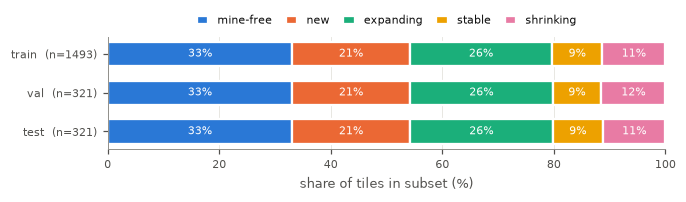

In [7]:
cat_tab = pd.crosstab(tiles.split, tiles.category, normalize="index").reindex(SPLITS) * 100
cat_counts = pd.crosstab(tiles.split, tiles.category, margins=True, margins_name="total")
cat_counts.to_csv(TAB / "split_change_categories.csv")
display(cat_counts)

cat_cols = [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"]]
fig, ax = plt.subplots(figsize=(FULL_W, 1.9))
left = np.zeros(len(SPLITS))
for cat, col in zip(CATEGORIES, cat_cols):
    v = cat_tab[cat].values
    ax.barh(SPLITS, v, left=left, color=col, edgecolor="white", linewidth=1.5, height=0.62, label=cat)
    for i, (l, w) in enumerate(zip(left, v)):
        if w >= 6:
            ax.text(l + w / 2, i, f"{w:.0f}%", ha="center", va="center", fontsize=7, color="white")
    left += v
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("share of tiles in subset (%)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), handlelength=1, columnspacing=1.2)
ax.set_yticks(range(3), [f"{s}  (n={int((tiles.split == s).sum())})" for s in SPLITS])
plt.tight_layout()
save(fig, "fig_split_balance")

NUMBERS["max_category_share_gap_between_splits_pp"] = round(float((cat_tab.max() - cat_tab.min()).max()), 2)

## 4. Published split disagreement and spatial adjacency (§1.3 gap 4, §2.3, §2.10)

The tiles sit on a regular 1,280 m grid (each GeoTIFF's origin is a multiple of the tile size
from a common offset), so every tile has a row/column index and its neighbours can be found
exactly. Two maps:

- **(a)** the new tile split, coloured by subset;
- **(b)** the published per-year split, highlighting tiles assigned differently in 2016 and 2022.

The adjacency statistic turns the §2.10 limitation into a number: the share of validation and
test tiles that touch at least one training tile (4-neighbour = shared edge, 8-neighbour =
shared edge or corner).

In [8]:
geo = samples[samples.year == "2016"][["tile", "x0", "y0"]].copy()
geo["col"] = np.rint((geo.x0 - geo.x0.min()) / TILE_M).astype(int)
geo["row"] = np.rint((geo.y0.max() - geo.y0) / TILE_M).astype(int)
assert np.allclose((geo.x0 - geo.x0.min()) % TILE_M, 0) and np.allclose((geo.y0.max() - geo.y0) % TILE_M, 0), \
    "tiles are not on a regular grid"
tiles = tiles.drop(columns=["row", "col"], errors="ignore").merge(geo[["tile", "row", "col"]], on="tile")

wide = pub.pivot(index="tile", columns="year", values="split")
tiles["pub_disagree"] = tiles.tile.map(wide["2016"] != wide["2022"])
NUMBERS["published_split_disagree_pct"] = round(100 * tiles.pub_disagree.mean(), 1)
NUMBERS["published_split_disagree_tiles"] = int(tiles.pub_disagree.sum())
cross = pd.crosstab(wide["2016"], wide["2022"], rownames=["2016 split"], colnames=["2022 split"])
cross.to_csv(TAB / "published_split_crosstab.csv")
display(cross)

pos = {(r, c): s for r, c, s in zip(tiles.row, tiles.col, tiles.split)}
N4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]
N8 = N4 + [(-1, -1), (-1, 1), (1, -1), (1, 1)]


def touches_train(r, c, offs):
    return any(pos.get((r + dr, c + dc)) == "train" for dr, dc in offs)


adj = {}
for sp in ("val", "test"):
    sub = tiles[tiles.split == sp]
    for name, offs in (("4", N4), ("8", N8)):
        share = 100 * np.mean([touches_train(r, c, offs) for r, c in zip(sub.row, sub.col)])
        adj[(sp, f"{name}-neighbour")] = share
        NUMBERS[f"{sp}_tiles_touching_train_{name}nbr_pct"] = round(share, 1)
adj = pd.Series(adj).unstack().round(1)
adj.to_csv(TAB / "adjacency_to_train.csv")
print("% of tiles with at least one training-tile neighbour:")
display(adj)
NUMBERS["study_grid_rows_cols"] = f"{tiles.row.max() + 1} x {tiles.col.max() + 1} tiles"

2022 split,test,train
2016 split,,
test,192,451
train,452,1040


% of tiles with at least one training-tile neighbour:


,4-neighbour,8-neighbour
test,99.1,100.0
val,99.1,100.0


saved output\dataset_analysis\figures\fig_split_map.png


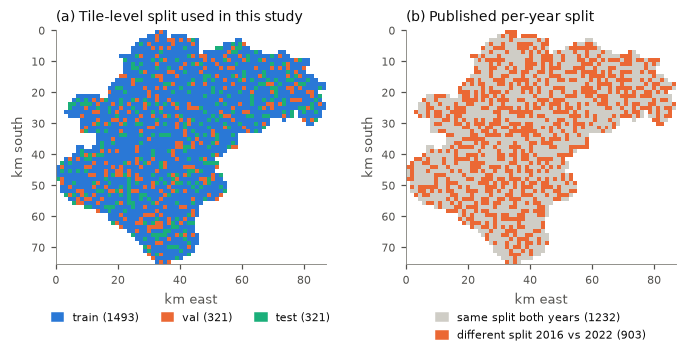

In [9]:
H, W = tiles.row.max() + 1, tiles.col.max() + 1
grid_split = np.full((H, W), np.nan)
grid_pub = np.full((H, W), np.nan)
for r, c, s, d in zip(tiles.row, tiles.col, tiles.split, tiles.pub_disagree):
    grid_split[r, c] = SPLITS.index(s)
    grid_pub[r, c] = int(d)

km = TILE_M / 1000
extent = [0, W * km, H * km, 0]
fig, axes = plt.subplots(1, 2, figsize=(FULL_W, FULL_W * 0.5 * H / W + 0.7))
panels = [
    (grid_split, [SPLIT_COL[s] for s in SPLITS],
     [f"{s} ({int((tiles.split == s).sum())})" for s in SPLITS], "(a) Tile-level split used in this study"),
    (grid_pub, ["#cfcdc6", C["orange"]],
     [f"same split both years ({int((~tiles.pub_disagree).sum())})",
      f"different split 2016 vs 2022 ({int(tiles.pub_disagree.sum())})"],
     "(b) Published per-year split"),
]
for ax, (g, cols, labels, title) in zip(axes, panels):
    ax.imshow(np.ma.masked_invalid(g), cmap=ListedColormap(cols), vmin=0, vmax=len(cols) - 1,
              interpolation="nearest", extent=extent)
    ax.set_title(title, loc="left")
    ax.set_xlabel("km east"); ax.set_ylabel("km south")
    ax.grid(False)
    ax.legend([Patch(color=c) for c in cols], labels, loc="upper center",
              bbox_to_anchor=(0.5, -0.16), ncol=1 if len(cols) == 2 else 3, handlelength=1)
plt.tight_layout()
save(fig, "fig_split_map")

## 5. Per-channel values (Table 1, §2.4)

**Radar scale check first.** §2.4 says the backscatter range is checked on loading to confirm
it is in decibels. It is not uniform across the dataset: files whose VV/VH values are all
non-negative hold **linear power**, not dB. The table below counts those files per year.
Everywhere else in this notebook such files are converted with 10·log₁₀ so both years share
one scale; any training pipeline that pools the years must do the same., standard deviation, minimum and maximum over every valid pixel; percentiles from
the uniform pixel sample. This doubles as the §2.4 check that Sentinel-1 is in decibels
(values negative, roughly −30 to +5 dB) rather than linear power (small positive numbers).

The training-split mean / std in `tables/normalisation_train.csv` are the statistics the
task-specific networks are standardised with.

In [10]:
mom = scan["moments"]  # (sample, [sum, sumsq, count, min, max], band)
s1_scale = samples.groupby("year").agg(files=("tile", "size"), linear_files=("s1_linear", "sum"),
                                       raw_VV_median=("vv_raw_median", "median"))
s1_scale["linear_files"] = s1_scale.linear_files.astype(int)
s1_scale["raw_VV_median_as_dB"] = np.where(s1_scale.linear_files == s1_scale.files,
                                           10 * np.log10(s1_scale.raw_VV_median), s1_scale.raw_VV_median)
s1_scale = s1_scale.round(3)
s1_scale.to_csv(TAB / "s1_scale_check.csv")
display(s1_scale)
for y_ in YEARS:
    n_lin, n = int(s1_scale.loc[y_, "linear_files"]), int(s1_scale.loc[y_, "files"])
    NUMBERS[f"s1_scale_{y_}"] = "linear power" if n_lin == n else ("dB" if n_lin == 0 else f"mixed ({n_lin}/{n} linear)")
print({k: v for k, v in NUMBERS.items() if k.startswith("s1_scale")})


def band_moments(idx):
    m = mom[idx]
    s, sq, n = m[:, 0].sum(0), m[:, 1].sum(0), m[:, 2].sum(0)
    mean = s / n
    return mean, np.sqrt(sq / n - mean ** 2), m[:, 3].min(0), m[:, 4].max(0), n


mean, std, mn, mx, n = band_moments(np.arange(len(samples)))
up = scan["pix"]["uniform"]
p1, p50, p99 = np.percentile(up, [1, 50, 99], axis=0)
band_table = pd.DataFrame({
    "channel": list(range(13)), "band": BANDS, "name": BAND_LONG, "sensor": SENSOR, "unit": UNITS,
    "min": mn, "p1": p1, "median": p50, "mean": mean, "p99": p99, "max": mx, "std": std,
    "nodata pixels": (len(samples) * 128 * 128 - n).astype(int),
}).round(2)
band_table.to_csv(TAB / "channel_statistics.csv", index=False)
display(band_table)

tr = np.flatnonzero(samples.split.values == "train")
tmean, tstd, *_ = band_moments(tr)
pd.DataFrame({"band": BANDS, "mean": tmean, "std": tstd}).round(4).to_csv(TAB / "normalisation_train.csv", index=False)

vv, vh = band_table.iloc[10], band_table.iloc[11]
NUMBERS["VV_p1_p99_dB"] = f"{vv.p1:.1f} to {vv.p99:.1f}"
NUMBERS["VH_p1_p99_dB"] = f"{vh.p1:.1f} to {vh.p99:.1f}"
NUMBERS["DEM_min_max_m"] = f"{band_table.iloc[12]['min']:.0f} to {band_table.iloc[12]['max']:.0f}"

c:\Users\Owner\Desktop\Augustus Amedume Comp Sci Degree\Augustus Amedume Year 4 Computer Science\Semester 2\Technology Research Methods\IllegalMiningDetection\.venv\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


,files,linear_files,raw_VV_median,raw_VV_median_as_dB
year,,,,
2016,2135,0,-7.236,-7.236
2022,2135,2135,0.182,-7.397


{'s1_scale_2016': 'dB', 's1_scale_2022': 'linear power'}


,channel,band,name,sensor,unit,min,p1,median,mean,p99,max,std,nodata pixels
0,0,B2,blue,Sentinel-2 L2A,reflectance x 10^4,908.00,1222.00,1437.00,1473.81,2204.00,55537.00,223.44,0
1,1,B3,green,Sentinel-2 L2A,reflectance x 10^4,1097.00,1420.00,1638.00,1703.35,2870.00,13528.00,285.54,0
2,2,B4,red,Sentinel-2 L2A,reflectance x 10^4,1065.00,1349.00,1561.00,1696.68,3376.00,13496.00,413.82,0
3,3,B5,red edge 1,Sentinel-2 L2A,reflectance x 10^4,1243.00,1679.00,2006.00,2105.88,3708.00,14033.00,395.83,0
4,4,B6,red edge 2,Sentinel-2 L2A,reflectance x 10^4,1222.00,2448.00,3113.00,3133.47,3991.00,13512.00,312.48,0
5,5,B7,red edge 3,Sentinel-2 L2A,reflectance x 10^4,1253.00,2646.00,3534.00,3543.18,4421.00,13229.00,354.47,0
6,6,B8,NIR,Sentinel-2 L2A,reflectance x 10^4,1212.00,2610.00,3675.00,3677.27,4637.00,13336.00,397.92,0
7,7,B8A,narrow NIR,Sentinel-2 L2A,reflectance x 10^4,1252.00,2733.00,3837.50,3832.40,4732.00,13073.00,389.62,0
8,8,B11,SWIR 1,Sentinel-2 L2A,reflectance x 10^4,852.00,2327.00,3081.00,3156.11,4669.00,16914.00,451.50,0
9,9,B12,SWIR 2,Sentinel-2 L2A,reflectance x 10^4,1128.00,1669.00,2085.00,2226.07,3998.00,16634.00,468.27,0


## 6. How well does each channel separate mine from background? (RQ1 motivation)

Class-conditional distributions from the balanced pixel samples (equal numbers of mine and
background pixels per sample where available). The number in each panel is a **single-band
AUC**: the probability that a random mine pixel has a higher value than a random background
pixel, folded so 0.5 = no separation and 1.0 = perfect separation in either direction. It is a
univariate screen, not a prediction of what a model can learn from band combinations.

,band,name,sensor,AUC (folded),mine vs background,median mine,median background
3,B5,red edge 1,Sentinel-2 L2A,0.961,higher,2849.000000,1995.000000
1,B3,green,Sentinel-2 L2A,0.958,higher,2202.000000,1631.000000
2,B4,red,Sentinel-2 L2A,0.957,higher,2518.000000,1553.000000
0,B2,blue,Sentinel-2 L2A,0.946,higher,1778.000000,1432.000000
11,VH,backscatter,Sentinel-1 RTC,0.809,lower,-15.024000,-13.124000
9,B12,SWIR 2,Sentinel-2 L2A,0.803,higher,2810.000000,2076.000000
10,VV,backscatter,Sentinel-1 RTC,0.794,lower,-9.005000,-7.283000
8,B11,SWIR 1,Sentinel-2 L2A,0.697,higher,3563.000000,3073.000000
12,DEM,elevation,Copernicus DEM,0.660,lower,159.514008,183.272003
4,B6,red edge 2,Sentinel-2 L2A,0.653,higher,3279.000000,3103.000000


saved output\dataset_analysis\figures\fig_band_distributions.png


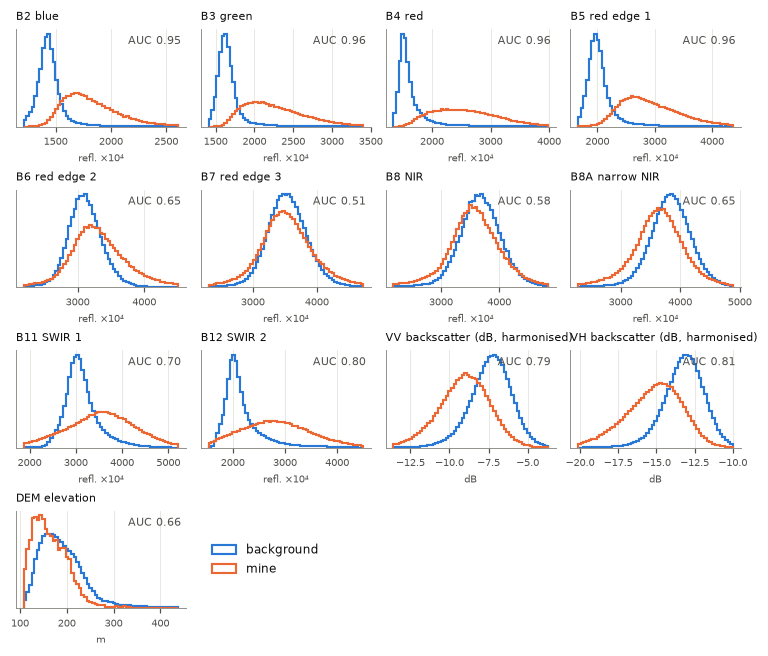

In [24]:
pm, pb = scan["pix"]["mine"], scan["pix"]["bg"]
y = np.r_[np.ones(len(pm)), np.zeros(len(pb))]
auc_rows = []
for b in range(13):
    a = roc_auc_score(y, np.r_[pm[:, b], pb[:, b]])
    auc_rows.append({"band": BANDS[b], "name": BAND_LONG[b], "sensor": SENSOR[b],
                     "AUC (folded)": max(a, 1 - a),
                     "mine vs background": "higher" if a > 0.5 else "lower",
                     "median mine": np.median(pm[:, b]), "median background": np.median(pb[:, b])})
auc = pd.DataFrame(auc_rows).round(3)
auc.to_csv(TAB / "band_separability_auc.csv", index=False)
display(auc.sort_values("AUC (folded)", ascending=False))

for grp, idx in (("S2", S2), ("S1", S1)):
    NUMBERS[f"best_{grp}_band_auc"] = f"{auc.iloc[idx]['AUC (folded)'].max():.3f} ({auc.iloc[idx].sort_values('AUC (folded)').iloc[-1].band})"
NUMBERS["DEM_auc"] = float(auc.iloc[DEM]["AUC (folded)"])

fig, axes = plt.subplots(4, 4, figsize=(FULL_W, FULL_W * 0.86))
for b, ax in enumerate(axes.flat[:13]):
    lo, hi = np.percentile(np.r_[pm[:, b], pb[:, b]], [0.5, 99.5])
    bins = np.linspace(lo, hi, 60)
    for data, col, lab in ((pb[:, b], BG, "background"), (pm[:, b], MINE, "mine")):
        ax.hist(data, bins=bins, density=True, histtype="step", color=col, linewidth=1.4, label=lab)
    ax.set_title(f"{BANDS[b]} {BAND_LONG[b]}" + (" (dB, harmonised)" if b in S1 else ""), fontsize=7.5, loc="left")
    ax.text(0.97, 0.93, f"AUC {auc.iloc[b]['AUC (folded)']:.2f}", transform=ax.transAxes,
            ha="right", va="top", fontsize=7, color=INK2)
    ax.set_yticks([])
    ax.tick_params(axis="x", labelsize=6.5)
    ax.set_xlabel(UNITS[b].replace("reflectance x 10^4", "refl. ×10⁴"), fontsize=6.5)
for ax in axes.flat[13:]:
    ax.axis("off")
axes.flat[13].legend(*axes.flat[0].get_legend_handles_labels(), loc="center left", fontsize=8)
plt.tight_layout(h_pad=0.6, w_pad=0.6)
save(fig, "fig_band_distributions")

## 7. Spearman correlation between channels (comparison with Ade et al., 2026)

Ade et al. report a median Spearman correlation of −0.72 between Sentinel-1 and the optical
bands on their Ghanaian data. The same quantity here: the median of the 20 VV/VH × S2-band
coefficients, computed on the uniform pixel sample (all land cover) and on mine pixels only.

,all pixels,mine pixels
median S1 x S2,-0.297,-0.163
min S1 x S2,-0.383,-0.373
max S1 x S2,0.179,-0.038
median S1 x DEM,0.052,0.080
median S2 x DEM,-0.013,-0.052


saved output\dataset_analysis\figures\fig_spearman.png


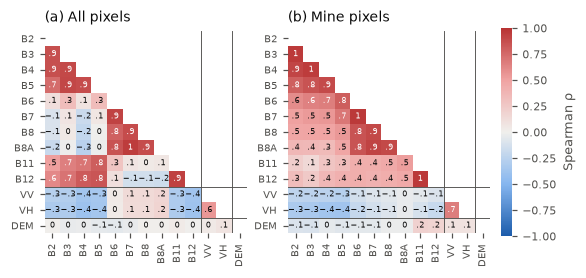

In [12]:
rho_all = stats.spearmanr(up).statistic
rho_mine = stats.spearmanr(pm).statistic
pd.DataFrame(rho_all, index=BANDS, columns=BANDS).round(3).to_csv(TAB / "spearman_all_pixels.csv")
pd.DataFrame(rho_mine, index=BANDS, columns=BANDS).round(3).to_csv(TAB / "spearman_mine_pixels.csv")

s1s2 = lambda r: r[np.ix_(S1, S2)]
corr_summary = pd.DataFrame({
    "all pixels": [np.median(s1s2(rho_all)), s1s2(rho_all).min(), s1s2(rho_all).max(),
                   np.median(rho_all[np.ix_(S1, [DEM])]), np.median(rho_all[np.ix_(S2, [DEM])])],
    "mine pixels": [np.median(s1s2(rho_mine)), s1s2(rho_mine).min(), s1s2(rho_mine).max(),
                    np.median(rho_mine[np.ix_(S1, [DEM])]), np.median(rho_mine[np.ix_(S2, [DEM])])],
}, index=["median S1 x S2", "min S1 x S2", "max S1 x S2", "median S1 x DEM", "median S2 x DEM"]).round(3)
corr_summary.to_csv(TAB / "spearman_summary.csv")
display(corr_summary)
NUMBERS["median_spearman_S1_S2_all"] = float(corr_summary.loc["median S1 x S2", "all pixels"])
NUMBERS["median_spearman_S1_S2_mine"] = float(corr_summary.loc["median S1 x S2", "mine pixels"])
NUMBERS["median_spearman_VV_VH_all"] = round(float(rho_all[10, 11]), 3)

fig, axes = plt.subplots(1, 2, figsize=(FULL_W, FULL_W * 0.52))
for ax, rho, title in ((axes[0], rho_all, "(a) All pixels"), (axes[1], rho_mine, "(b) Mine pixels")):
    shown = np.where(np.tril(np.ones((13, 13), bool), -1), rho, np.nan)
    im = ax.imshow(shown, cmap=DIVERGING, vmin=-1, vmax=1)
    for i in range(13):
        for j in range(i):
            v = f"{rho[i, j]:.1f}"
            v = {"1.0": "1", "-1.0": "−1", "0.0": "0", "-0.0": "0"}.get(v, v.replace("0.", ".").replace("-", "−"))
            ax.text(j, i, v,
                    ha="center", va="center", fontsize=5.2,
                    color="white" if abs(rho[i, j]) > 0.6 else INK)
    ax.set_xticks(range(13), BANDS, rotation=90, fontsize=6.5)
    ax.set_yticks(range(13), BANDS, fontsize=6.5)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    for k in (9.5, 11.5):  # sensor boundaries
        ax.axhline(k, color=INK2, lw=0.6); ax.axvline(k, color=INK2, lw=0.6)
    ax.set_title(title, loc="left")
cb = fig.colorbar(im, ax=axes, shrink=0.75, pad=0.02)
cb.set_label("Spearman ρ"); cb.outline.set_visible(False)
save(fig, "fig_spearman")

## 8. Elevation inside and outside mines (label-derivation limitation)

The reference labels were classified using elevation. If mines sit at systematically
different elevations, a model given the DEM can partly recover the labelling rule — which is
why the A4 − A3 contrast must be read cautiously.

In [13]:
dem = pd.DataFrame({
    "mine": pd.Series(pm[:, DEM]).describe(percentiles=[.1, .25, .5, .75, .9]),
    "background": pd.Series(pb[:, DEM]).describe(percentiles=[.1, .25, .5, .75, .9]),
}).drop("count").round(1)
dem.to_csv(TAB / "elevation_mine_vs_background.csv")
display(dem)
NUMBERS["median_elev_mine_m"] = float(dem.loc["50%", "mine"])
NUMBERS["median_elev_background_m"] = float(dem.loc["50%", "background"])

# Elevation relative to each tile's own minimum: mines in valley floors show up here even
# where absolute elevation varies across the study area.
rel = []
for key in ("mine", "bg"):
    ids = scan["pix_id"][key]
    tile_min = mom[ids, 3, DEM]
    rel.append(scan["pix"][key][:, DEM] - tile_min)
NUMBERS["median_height_above_tile_min_mine_m"] = round(float(np.median(rel[0])), 1)
NUMBERS["median_height_above_tile_min_background_m"] = round(float(np.median(rel[1])), 1)
y_rel = np.r_[np.ones(len(rel[0])), np.zeros(len(rel[1]))]
a = roc_auc_score(y_rel, np.r_[rel[0], rel[1]])
NUMBERS["relative_elevation_auc"] = round(max(a, 1 - a), 3)
print({k: NUMBERS[k] for k in NUMBERS if "elev" in k or "tile_min" in k})

,mine,background
mean,165.8,193.5
std,38.8,57.2
min,84.6,77.0
10%,121.8,137.0
25%,135.9,155.3
50%,159.5,183.3
75%,190.1,217.4
90%,215.0,252.8
max,424.5,717.2


{'median_elev_mine_m': 159.5, 'median_elev_background_m': 183.3, 'median_height_above_tile_min_mine_m': 7.0, 'median_height_above_tile_min_background_m': 21.3, 'relative_elevation_auc': 0.846}


## 9. Size of individual mining patches (§1.1, §2.4)

Connected regions of mine pixels (8-connectivity) in each mask. Patches touching the tile
border are truncated by the 1.28 km tile, so their true size is larger; they are kept in the
histogram but counted separately.

,patches,median_ha,mean_ha,p90_ha,under_10px_pct,under_1ha_pct,edge_truncated_pct
year,,,,,,,
2016,3736.0,0.69,5.14,12.03,8.43,58.11,54.68
2022,7522.0,0.52,3.56,6.64,8.28,64.09,49.52
all,11258.0,0.57,4.09,8.19,8.33,62.11,51.23


saved output\dataset_analysis\figures\fig_mine_patch_sizes.png


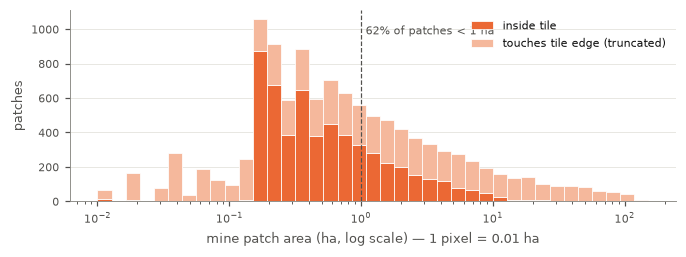

In [14]:
comp = scan["components"].copy()
comp["ha"] = comp.px * PIXEL_HA
by_year = comp.groupby("year").agg(patches=("px", "size"), median_ha=("ha", "median"),
                                   mean_ha=("ha", "mean"), p90_ha=("ha", lambda v: v.quantile(.9)),
                                   under_10px_pct=("px", lambda v: 100 * (v < 10).mean()),
                                   under_1ha_pct=("ha", lambda v: 100 * (v < 1).mean()),
                                   edge_truncated_pct=("edge", lambda v: 100 * v.mean())).round(2)
interior = comp[~comp.edge]
by_year.loc["all"] = [len(comp), comp.ha.median(), comp.ha.mean(), comp.ha.quantile(.9),
                      100 * (comp.px < 10).mean(), 100 * (comp.ha < 1).mean(), 100 * comp.edge.mean()]
by_year = by_year.round(2)
by_year.to_csv(TAB / "mine_patch_sizes.csv")
display(by_year)
NUMBERS["mine_patches_total"] = int(len(comp))
NUMBERS["mine_patch_median_ha"] = round(float(comp.ha.median()), 2)
NUMBERS["mine_patch_interior_median_ha"] = round(float(interior.ha.median()), 2)
NUMBERS["mine_patches_under_1ha_pct"] = round(float(100 * (comp.ha < 1).mean()), 1)
NUMBERS["mine_patches_under_10px_pct"] = round(float(100 * (comp.px < 10).mean()), 1)
NUMBERS["share_of_mine_area_in_patches_under_1ha_pct"] = round(float(100 * comp.ha[comp.ha < 1].sum() / comp.ha.sum()), 1)

fig, ax = plt.subplots(figsize=(FULL_W, 2.4))
bins = np.logspace(np.log10(PIXEL_HA), np.log10(comp.ha.max()), 40)
ax.hist([comp.ha[~comp.edge], comp.ha[comp.edge]], bins=bins, stacked=True,
        color=[MINE, "#f5b89c"], edgecolor="white", linewidth=0.5,
        label=["inside tile", "touches tile edge (truncated)"])
ax.set_xscale("log")
ax.set_xlabel("mine patch area (ha, log scale) — 1 pixel = 0.01 ha")
ax.set_ylabel("patches")
ax.axvline(1, color=INK2, lw=0.8, ls="--")
ax.text(1.08, ax.get_ylim()[1] * 0.92, f"{NUMBERS['mine_patches_under_1ha_pct']:.0f}% of patches < 1 ha",
        fontsize=7.5, color=INK2, va="top")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
save(fig, "fig_mine_patch_sizes")

## 10. What happened to each pixel between 2016 and 2022 (§1.1)

In [15]:
tr_ = scan["transitions"][["bg_bg", "bg_mine", "mine_mine", "mine_bg"]].sum()
transitions = pd.DataFrame({
    "pixels": tr_, "hectares": tr_ * PIXEL_HA, "% of all pixels": 100 * tr_ / tr_.sum(),
}).rename(index={"bg_bg": "background in both years", "bg_mine": "new mining (background → mine)",
                 "mine_mine": "persistent mining (mine in both)", "mine_bg": "mine → background"}).round(2)
mine16 = tr_.mine_mine + tr_.mine_bg
transitions.loc["2016 mine pixels still mine in 2022 (%)"] = [np.nan, np.nan, 100 * tr_.mine_mine / mine16]
transitions.loc["2022 mine pixels that were new (%)"] = [np.nan, np.nan, 100 * tr_.bg_mine / (tr_.bg_mine + tr_.mine_mine)]
transitions = transitions.round(2)
transitions.to_csv(TAB / "pixel_transitions_2016_2022.csv")
display(transitions)
NUMBERS["new_mining_ha"] = round(float(tr_.bg_mine * PIXEL_HA), 0)
NUMBERS["mine_to_background_ha"] = round(float(tr_.mine_bg * PIXEL_HA), 0)
NUMBERS["net_mining_change_ha"] = round(float((tr_.bg_mine - tr_.mine_bg) * PIXEL_HA), 0)
NUMBERS["mine2016_persisting_pct"] = round(float(100 * tr_.mine_mine / mine16), 1)
NUMBERS["mine2022_new_pct"] = round(float(100 * tr_.bg_mine / (tr_.bg_mine + tr_.mine_mine)), 1)
NUMBERS["tile_change_categories"] = tiles.category.value_counts().reindex(CATEGORIES).to_dict()

,pixels,hectares,% of all pixels
background in both years,31549195.0,315491.95,90.19
new mining (background → mine),1509061.0,15090.61,4.31
persistent mining (mine in both),1168457.0,11684.57,3.34
mine → background,753127.0,7531.27,2.15
2016 mine pixels still mine in 2022 (%),NaN,NaN,60.81
2022 mine pixels that were new (%),NaN,NaN,56.36


## 11. How much haze or cloud is there? (§2.10 limited cloud variation)

Proxy: mean blue (B2) reflectance over each sample's **non-mine** pixels. Mine pixels are
excluded because bright, turbid mining ponds resemble haze in the visible bands. Clear
vegetated land sits low; haze and thin cloud push the value up. A narrow distribution with a
short right tail supports "predominantly clear" conditions.

,count,mean,std,min,25%,50%,75%,95%,99%,max,IQR / median
year,,,,,,,,,,,
2016,2135.0,1440.0,113.0,1235.0,1381.0,1438.0,1488.0,1563.0,1780.0,2814.0,0.07
2022,2135.0,1456.0,65.0,1257.0,1421.0,1454.0,1484.0,1562.0,1670.0,2265.0,0.04


saved output\dataset_analysis\figures\fig_haze_proxy.png


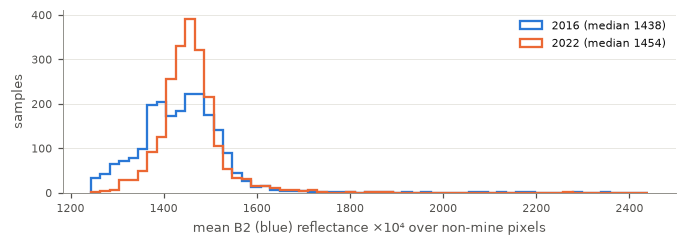

In [16]:
hz = samples.dropna(subset=["haze_blue"])
haze = hz.groupby("year").haze_blue.describe(percentiles=[.25, .5, .75, .95, .99]).round(0)
haze["IQR / median"] = ((haze["75%"] - haze["25%"]) / haze["50%"]).round(2)
haze.to_csv(TAB / "haze_proxy.csv")
display(haze)
for y_ in YEARS:
    NUMBERS[f"haze_blue_median_{y_}"] = float(haze.loc[y_, "50%"])
    NUMBERS[f"haze_blue_iqr_over_median_{y_}"] = float(haze.loc[y_, "IQR / median"])

fig, ax = plt.subplots(figsize=(FULL_W, 2.3))
bins = np.linspace(hz.haze_blue.quantile(0.001), hz.haze_blue.quantile(0.999), 60)
for y_, col in zip(YEARS, (C["blue"], C["orange"])):
    ax.hist(hz.haze_blue[hz.year == y_], bins=bins, histtype="step", linewidth=1.5, color=col,
            label=f"{y_} (median {haze.loc[y_, '50%']:.0f})")
ax.set_xlabel("mean B2 (blue) reflectance ×10⁴ over non-mine pixels")
ax.set_ylabel("samples")
ax.legend()
ax.grid(axis="x", visible=False)
plt.tight_layout()
save(fig, "fig_haze_proxy")

## 12. What each input arm sees (§2.2, Table 2)

One tile, every input source. A1 = Sentinel-2 (shown as true colour and a SWIR composite),
A2 = VV + VH, A4 adds the DEM. Orange outline = reference mask.

saved output\dataset_analysis\figures\fig_example_tile_by_arm.png


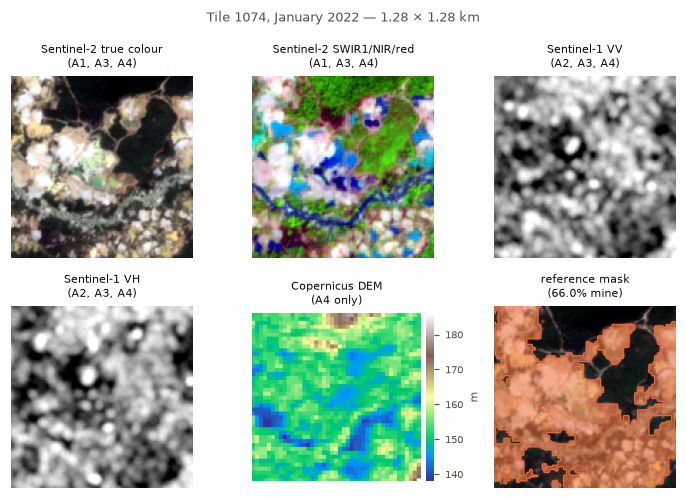

In [17]:
EXAMPLE = ("2022", "1074")
image, mask = load_patch(*EXAMPLE)
panels = [
    (composite(image, (RED, GREEN, BLUE)), None, "Sentinel-2 true colour\n(A1, A3, A4)"),
    (composite(image, (SWIR1, NIR, RED)), None, "Sentinel-2 SWIR1/NIR/red\n(A1, A3, A4)"),
    (stretch(image[10]), "gray", "Sentinel-1 VV\n(A2, A3, A4)"),
    (stretch(image[11]), "gray", "Sentinel-1 VH\n(A2, A3, A4)"),
    (image[DEM], "terrain", "Copernicus DEM\n(A4 only)"),
    (composite(image, (RED, GREEN, BLUE)), None, f"reference mask\n({100 * (mask == 1).mean():.1f}% mine)"),
]
fig, axes = plt.subplots(2, 3, figsize=(FULL_W, FULL_W * 0.74))
for i, (ax, (data, cmap, title)) in enumerate(zip(axes.flat, panels)):
    im = ax.imshow(data, cmap=cmap)
    if i == 4:
        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("m", fontsize=7)
        cb.outline.set_visible(False); cb.ax.tick_params(labelsize=6.5)
    if i == 5:
        ax.imshow(np.ma.masked_where(mask != 1, mask), cmap=ListedColormap([MINE]), alpha=0.55)
        outline(ax, mask)
    ax.set_title(title, fontsize=7.5)
    bare(ax)
fig.suptitle(f"Tile {EXAMPLE[1]}, January {EXAMPLE[0]} — 1.28 × 1.28 km", fontsize=8.5, color=INK2)
plt.tight_layout()
save(fig, "fig_example_tile_by_arm")

## 13. The same tile in 2016 and 2022 (§2.3)

The tile with the largest increase in mine coverage. Field boundaries, roads and terrain are
shared between the two dates — the reason both years must sit in the same subset.

saved output\dataset_analysis\figures\fig_change_2016_2022.png


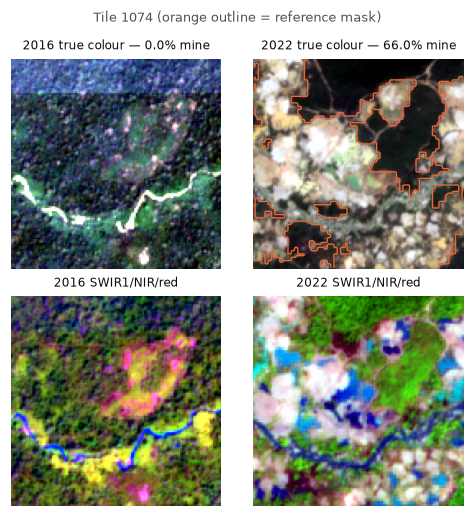

In [18]:
top = tiles.sort_values("delta", ascending=False).iloc[0]
NUMBERS["largest_growth_tile"] = f"{top.tile}: {top.pct_2016:.1f}% -> {top.pct_2022:.1f}%"
fig, axes = plt.subplots(2, 2, figsize=(FULL_W * 0.72, FULL_W * 0.75))
for col, y_ in enumerate(YEARS):
    image, mask = load_patch(y_, top.tile)
    axes[0, col].imshow(composite(image, (RED, GREEN, BLUE)))
    outline(axes[0, col], mask)
    axes[0, col].set_title(f"{y_} true colour — {100 * (mask == 1).mean():.1f}% mine", fontsize=8)
    axes[1, col].imshow(composite(image, (SWIR1, NIR, RED)))
    axes[1, col].set_title(f"{y_} SWIR1/NIR/red", fontsize=8)
    for ax in axes[:, col]:
        bare(ax)
fig.suptitle(f"Tile {top.tile} (orange outline = reference mask)", fontsize=8.5, color=INK2)
plt.tight_layout()
save(fig, "fig_change_2016_2022")

## 14. Prespecified tiles for the qualitative analysis (§2.8)

§2.8 commits to inspecting prediction maps on tiles showing **alluvial ponds, dry excavation
pits, cleared farmland and mine-free forest**, chosen *before* any predictions are seen. The
cell below shortlists candidates from the **test** split with simple spectral rules, then
shows them so the choice can be confirmed by eye:

| Category | Rule (test samples only) |
|---|---|
| alluvial ponds | ≥ 5% mine; highest share of mine pixels that are water (MNDWI > 0) |
| dry excavation pits | ≥ 5% mine; < 5% of mine pixels are water; ranked by mine coverage |
| cleared farmland | no mine pixels; highest share of sparse-vegetation pixels (NDVI < 0.4) |
| mine-free forest | no mine pixels; highest mean NDVI |

The rules only shortlist; **look at the gallery, then fix the four choices in `PICKS`** and
quote those tile IDs in §2.8. "Cleared farmland" by NDVI also catches settlements and roads, so
that row in particular needs a visual check.

saved output\dataset_analysis\figures\candidates_qualitative_tiles.png
alluvial ponds         0928/2022, 0928/2016, 1589/2016, 0423/2016, 0342/2016
dry excavation pits    0929/2022, 1550/2016, 0682/2022, 1368/2022, 1297/2022
cleared farmland       2105/2022, 2082/2022, 2081/2022, 2014/2022, 1966/2022
mine-free forest       1640/2022, 0962/2022, 1153/2022, 1279/2022, 0062/2016


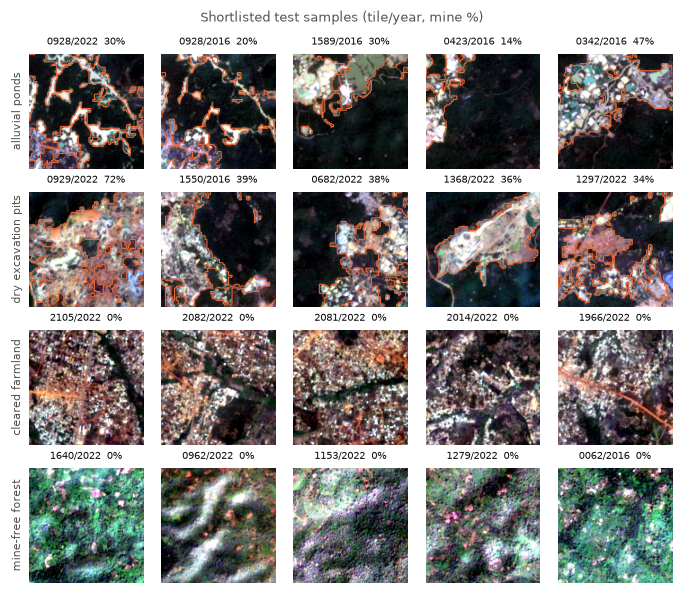

In [19]:
test = samples[samples.split == "test"].copy()
mined = test[test.pct >= 5]
free = test[test.n_mine == 0]
shortlist = {
    "alluvial ponds": mined.sort_values("water_frac_mine", ascending=False),
    "dry excavation pits": mined[mined.water_frac_mine < 0.05].sort_values("pct", ascending=False),
    "cleared farmland": free.sort_values("bare_frac_nonmine", ascending=False),
    "mine-free forest": free.sort_values("ndvi_nonmine", ascending=False),
}
N_CAND = 5
fig, axes = plt.subplots(4, N_CAND, figsize=(FULL_W, FULL_W * 4 / N_CAND + 0.4))
for r, (cat, df) in enumerate(shortlist.items()):
    for c in range(N_CAND):
        ax = axes[r, c]; bare(ax)
        if c >= len(df):
            continue
        row = df.iloc[c]
        image, mask = load_patch(row.year, row.tile)
        ax.imshow(composite(image, (RED, GREEN, BLUE)))
        outline(ax, mask, lw=0.7)
        ax.set_title(f"{row.tile}/{row.year}  {row.pct:.0f}%", fontsize=6.5)
    axes[r, 0].set_ylabel(cat, fontsize=7.5)
    axes[r, 0].yaxis.label.set_visible(True)
fig.suptitle("Shortlisted test samples (tile/year, mine %)", fontsize=8.5, color=INK2)
plt.tight_layout()
save(fig, "candidates_qualitative_tiles")  # working figure, not for the document

for cat, df in shortlist.items():
    print(f"{cat:22s}", ", ".join(f"{t}/{y}" for t, y in zip(df.tile[:N_CAND], df.year[:N_CAND])))

saved output\dataset_analysis\figures\fig_qualitative_tiles.png


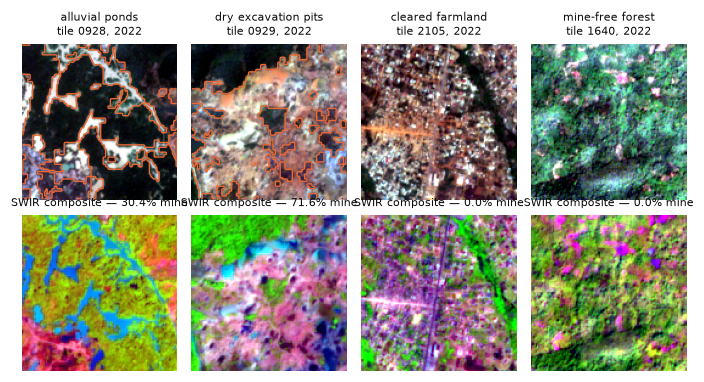

In [20]:
# Confirm visually, then edit. Defaults are the top-ranked candidate per category.
PICKS = {cat: (df.iloc[0].tile, df.iloc[0].year) for cat, df in shortlist.items()}
# e.g. PICKS["cleared farmland"] = ("0123", "2022")

pd.DataFrame([{"category": k, "tile": t, "year": y} for k, (t, y) in PICKS.items()]).to_csv(
    TAB / "qualitative_tiles.csv", index=False)
NUMBERS["qualitative_tiles"] = {k: f"{t}/{y}" for k, (t, y) in PICKS.items()}

fig, axes = plt.subplots(2, 4, figsize=(FULL_W, FULL_W * 0.55))
for c, (cat, (t, y_)) in enumerate(PICKS.items()):
    image, mask = load_patch(y_, t)
    axes[0, c].imshow(composite(image, (RED, GREEN, BLUE)))
    outline(axes[0, c], mask)
    axes[0, c].set_title(f"{cat}\ntile {t}, {y_}", fontsize=7.5)
    axes[1, c].imshow(composite(image, (SWIR1, NIR, RED)))
    axes[1, c].set_title(f"SWIR composite — {100 * (mask == 1).mean():.1f}% mine", fontsize=7)
    bare(axes[0, c]); bare(axes[1, c])
plt.tight_layout()
save(fig, "fig_qualitative_tiles")

## 15. Environment (§2.10)

Run this cell **in the Colab session that trains the models** as well — the document's
`[GPU model and memory]` placeholder and Python version should come from there, not from the
machine this analysis ran on.

In [21]:
env = {"python": platform.python_version(), "platform": platform.platform()}
for mod in ("numpy", "pandas", "rasterio", "scipy", "sklearn", "torch", "terratorch",
            "segmentation_models_pytorch", "lightning"):
    try:
        env[mod] = __import__(mod).__version__
    except Exception:
        env[mod] = "not installed"
try:
    import torch
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        env["gpu"] = f"{p.name}, {p.total_memory / 2**30:.0f} GB"
    else:
        env["gpu"] = "none (CPU)"
except Exception:
    env["gpu"] = "unknown"
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
display(pd.Series(env).to_frame("version"))

c:\Users\Owner\Desktop\Augustus Amedume Comp Sci Degree\Augustus Amedume Year 4 Computer Science\Semester 2\Technology Research Methods\IllegalMiningDetection\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,version
python,3.13.5
platform,Windows-11-10.0.26200-SP0
numpy,2.5.2
pandas,3.0.5
rasterio,1.5.1
scipy,1.18.1
sklearn,1.9.1
torch,2.14.0+cpu
terratorch,not installed
segmentation_models_pytorch,0.5.0


## 16. Numbers for the document

In [22]:
def fmt(v):
    if isinstance(v, dict):
        return ", ".join(f"{k}: {x}" for k, x in v.items())
    if isinstance(v, (float, np.floating)):
        return f"{v:,.3f}".rstrip("0").rstrip(".")
    if isinstance(v, (int, np.integer)):
        return f"{v:,}"
    return str(v)


lines = ["# Numbers for the document", "",
         f"Generated by `dataset_analysis.ipynb` (split stratification: `{STRATIFY}`, seed {SEED}).", "",
         "| key | value |", "|---|---|"]
lines += [f"| {k} | {fmt(v)} |" for k, v in NUMBERS.items()]
(OUT / "numbers_for_doc.md").write_text("\n".join(lines), encoding="utf-8")
(OUT / "numbers_for_doc.json").write_text(json.dumps(NUMBERS, indent=2, default=str), encoding="utf-8")
print("\n".join(lines))

# Numbers for the document

Generated by `dataset_analysis.ipynb` (split stratification: `change`, seed 42).

| key | value |
|---|---|
| mine_share_2016_pct | 5.49 |
| mine_free_samples_2016_pct | 54.1 |
| mine_share_2022_pct | 7.65 |
| mine_free_samples_2022_pct | 35 |
| mine_share_pooled_pct | 6.57 |
| background_share_pooled_pct | 93.43 |
| n_tiles | 2,135 |
| n_samples | 4,270 |
| mask_nodata_pixels | 0 |
| image_nodata_pixels | 0 |
| mask_values_seen | 0 and 1 only |
| max_abs_diff_mask_vs_csv_pp | 0.005 |
| split_stratification | change |
| train_tiles | 1,493 |
| train_mine_share_pct | 6.64 |
| val_tiles | 321 |
| val_mine_share_pct | 6.11 |
| test_tiles | 321 |
| test_mine_share_pct | 6.75 |
| max_category_share_gap_between_splits_pp | 0.31 |
| published_split_disagree_pct | 42.3 |
| published_split_disagree_tiles | 903 |
| val_tiles_touching_train_4nbr_pct | 99.1 |
| val_tiles_touching_train_8nbr_pct | 100 |
| test_tiles_touching_train_4nbr_pct | 99.1 |
| test_tiles_touching_